# 1. Import libraries

In [1]:
from nilearn.datasets import fetch_abide_pcp
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt
from nilearn import image, plotting

# 2. Preprocessing

## 2.1 Download dataset

In [2]:

abide = fetch_abide_pcp(
    data_dir='./data',
    pipeline='cpac',
    band_pass_filtering=True,
    global_signal_regression=False,
    derivatives=['func_preproc'],
    quality_checked=True,
    n_subjects=10
)
print(f"Subject number: {len(abide.func_preproc)}")

[fetch_abide_pcp] Dataset directory found: data\ABIDE_pcp
Subject number: 10


## 2.2 Load and visualize

In [3]:
# Get first subject
img_path = abide.func_preproc[0]
img_4d = nib.load(img_path)


# Get header information
print(f"Shape: {img_4d.shape}")

print(f"Voxel size : {img_4d.header.get_zooms()[:3]} mm")

print(f"Data type: {img_4d.header.get_data_dtype()}")

print(f"Timepoint number: {img_4d.shape[3]}")

Shape: (61, 73, 61, 196)
Voxel size : (np.float32(3.0), np.float32(3.0), np.float32(3.0)) mm
Data type: float64
Timepoint number: 196


In [4]:
# Get one frame
# Way1
data_4d = img_4d.get_fdata()
frame_t0 = data_4d[:, :, :,0]

# Way 2
img_3d_t0 = image.index_img(img_path, 0)


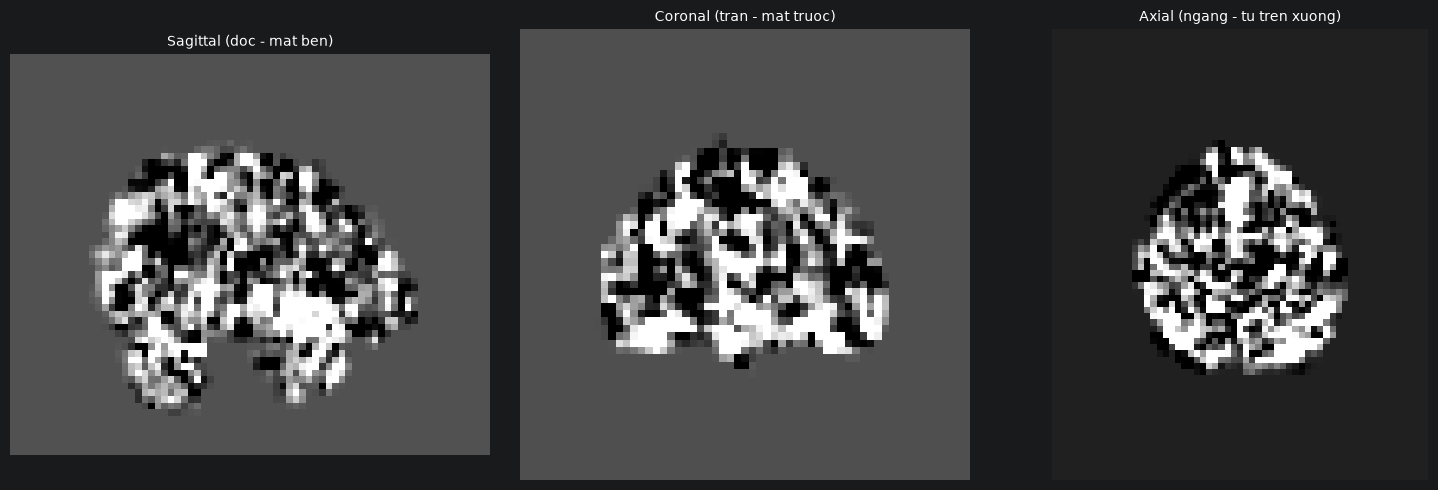

In [5]:
# Visualize 3 mat cat
def visualize_slices(vx, vy, vz):
    fig, axes = plt.subplots(1,3,figsize=(15,5))

    # Lay slice o cac mat
    slices = {
        "Sagittal (doc - mat ben)": frame_t0[vx,:,:].T,
        "Coronal (tran - mat truoc)": frame_t0[:,vy,:].T,
        "Axial (ngang - tu tren xuong)": frame_t0[:,:,vz].T,
    }

    for ax, (title, sl) in zip(axes, slices.items()):
        ax.imshow(sl, cmap="gray", origin="lower",
                  vmin=np.percentile(sl,5), vmax=np.percentile(sl,95))

        ax.set_title(title, fontsize=10)
        ax.axis('off')

    plt.tight_layout()
    plt.show()

visualize_slices(45, 54, 45)


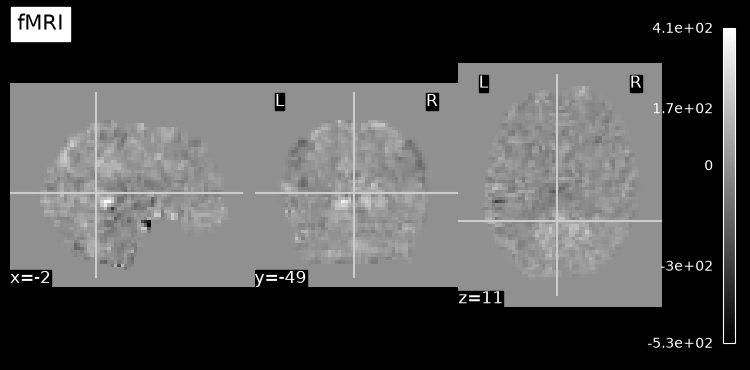

In [6]:
# Visualize voi nilearn
plotting.plot_epi(
    img_3d_t0,
    title="fMRI",
    display_mode="ortho",
    cmap="gray",
)

Selected voxel: 28,33,6


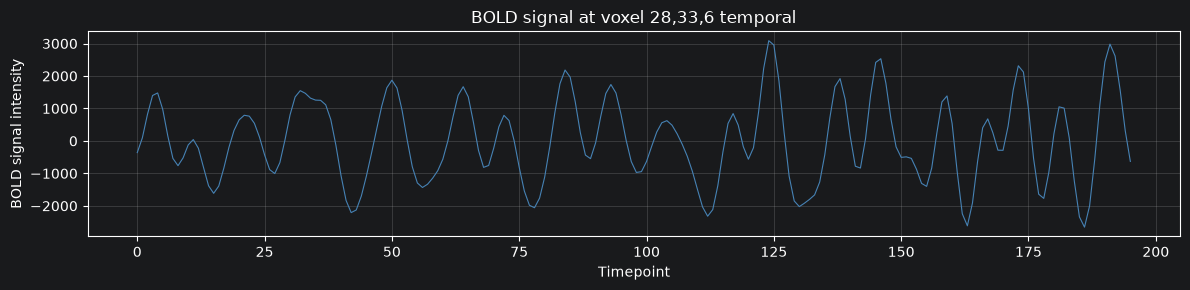

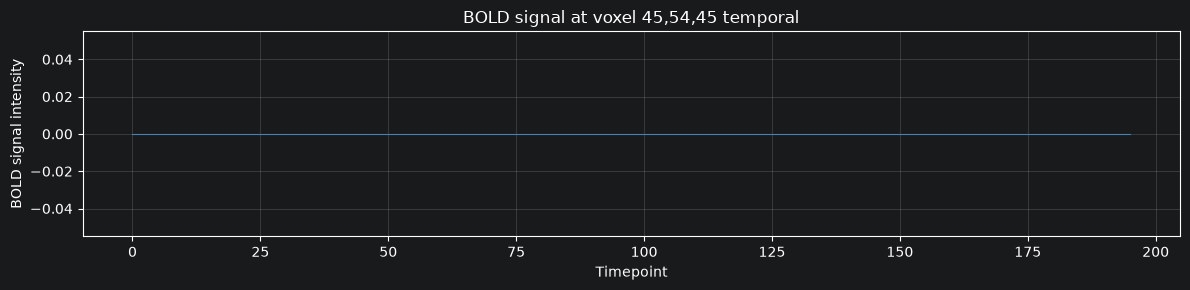

In [7]:
# Tinh do bien thien theo thoi gian
temporal_std = np.std(data_4d, axis=3)

# Tim voxel co do bien thien lon nhat
# Muc dich la de hien thi cho thay duoc su bien thien, khong khang dinh day la vung voxel quan trong nhat
vx, vy, vz = np.unravel_index(np.argmax(temporal_std), temporal_std.shape)

# Xem tin hieu theo thoi gian tai 1 voxel
# Select voxel at center
print(f"Selected voxel: {vx},{vy},{vz}")

def bold_signal(vx, vy, vz):
    signal_at_voxel = data_4d[vx, vy, vz, :]   # shape: (T,)
    plt.figure(figsize=(12, 3))
    plt.plot(signal_at_voxel,color="steelblue", linewidth=0.8)
    plt.xlabel("Timepoint")
    plt.ylabel("BOLD signal intensity")
    plt.title(f"BOLD signal at voxel {vx},{vy},{vz} temporal")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

bold_signal(vx, vy, vz)

# Thu lay vung giua nao
bold_signal(45, 54, 45)

## 2.3 Apply Atlas on 3D image - ROI Extraction

[fetch_atlas_aal] Dataset directory found: C:\Users\KietKlat\nilearn_data\aal_SPM12
Atlas: AAL (117 ROIs)
Ví dụ các vùng não: ['Background', 'Precentral_L', 'Precentral_R', 'Frontal_Sup_L', 'Frontal_Sup_R', 'Frontal_Sup_Orb_L', 'Frontal_Sup_Orb_R', 'Frontal_Mid_L']
→ Đã lưu: output/04_atlas_overlay.png


ValueError: operands could not be broadcast together with shapes (61,73,61) (91,109,91) 

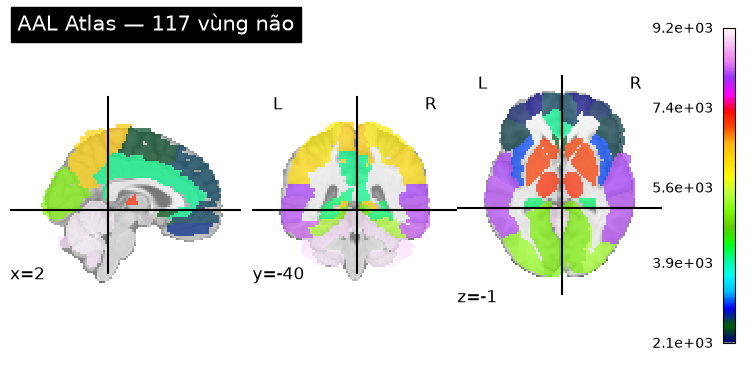

In [9]:
from nilearn.maskers import NiftiLabelsMasker
# step3_roi_extraction.py
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from nilearn import datasets, image, plotting

# ── Load Atlas AAL ──
atlas     = datasets.fetch_atlas_aal(version='SPM12')
atlas_img = atlas.maps
labels    = atlas.labels

print(f"Atlas: AAL ({len(labels)} ROIs)")
print(f"Ví dụ các vùng não: {labels[:8]}")


# ── Visualize Atlas overlay lên não ──
# Đây là kết quả tương tự như bạn thấy trong 3D Slicer
plotting.plot_roi(
    atlas_img,
    title=f'AAL Atlas — {len(labels)} vùng não',
    display_mode='ortho',
    colorbar=True,
    output_file='output/04_atlas_overlay.png'
)
print("→ Đã lưu: output/04_atlas_overlay.png")


# ── Minh họa Masking thủ công (1 ROI) ──
# Đây là bản chất của ROI extraction: ảnh × mask
atlas_data = image.load_img(atlas_img).get_fdata()
brain_data = image.load_img(image.index_img(abide.func_preproc[0], 0)).get_fdata()

roi_id   = 67   # Hippocampus_L — vùng quan trọng trong ASD
roi_name = labels[roi_id - 1]  # labels bắt đầu từ 0, ID từ 1

mask   = (atlas_data == roi_id).astype(float)   # binary mask: 0 hoặc 1
masked = brain_data * mask                       # ảnh × mask = signal trong ROI

# Tìm slice có ROI
z_slice = np.argmax(mask.sum(axis=(0,1)))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
fig.suptitle(f'Masking Operation — ROI: {roi_name} (ID={roi_id})', fontsize=12)

axes[0].imshow(brain_data[:, :, z_slice].T, cmap='gray', origin='lower')
axes[0].set_title('1. Ảnh não gốc (1 timepoint)')

axes[1].imshow(mask[:, :, z_slice].T, cmap='Reds', origin='lower', vmin=0, vmax=1)
axes[1].set_title('2. Binary Mask của ROI')

axes[2].imshow(masked[:, :, z_slice].T, cmap='hot', origin='lower')
axes[2].set_title('3. Ảnh sau Masking\n(chỉ còn tín hiệu trong ROI)')

for ax in axes: ax.axis('off')
plt.tight_layout()
plt.savefig('output/05_roi_masking.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"→ Đã lưu: output/05_roi_masking.png")


# ── Extract mean signal từ ROI (tính trung bình spatial) ──
roi_voxels = brain_data[mask > 0]   # lấy tất cả voxel trong ROI
mean_signal = roi_voxels.mean()     # mean signal tại timepoint này

print(f"\n→ ROI '{roi_name}': {int(mask.sum())} voxels, mean BOLD = {mean_signal:.4f}")


# ── Extract TIME SERIES cho tất cả ROI — dùng NiftiLabelsMasker ──
# (Làm tự động cho 116 ROI, không cần lặp thủ công)
masker = NiftiLabelsMasker(
    labels_img=atlas_img,
    standardize=True,      # zero-mean, unit variance
    memory='./cache',
    verbose=0
)

# Áp masker lên ảnh 4D → nhận time series
ts_sub0 = masker.fit_transform(abide.func_preproc[0])
# shape: (T, 116) — T timepoints, 116 ROIs

print(f"\nTime series shape: {ts_sub0.shape}")
print(f"  Rows (T)   = số timepoints = {ts_sub0.shape[0]}")
print(f"  Cols (N)   = số ROI       = {ts_sub0.shape[1]}")


# ── Visualize time series của vài ROI ──
plt.figure(figsize=(14, 4))
colors = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12', '#9b59b6']
for i, (label, color) in enumerate(zip(labels[:5], colors)):
    plt.plot(ts_sub0[:, i], label=label, color=color, alpha=0.85, linewidth=0.9)

plt.xlabel('Timepoint', fontsize=11)
plt.ylabel('BOLD Signal (standardized)', fontsize=11)
plt.title('ROI Time Series — Subject 01 (5 ROI đầu tiên)', fontsize=12)
plt.legend(fontsize=8, loc='upper right')
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig('output/06_roi_timeseries.png', dpi=150)
plt.show()
print("→ Đã lưu: output/06_roi_timeseries.png")